# Python Review: Functions, Classes, Vectorisation and Data Loading/Plotting

**Contents**
1. Functions
2. Classes
3. Vectorisation
4. Creating, saving, loading and plotting data

Cells marked **Example** can simply be run. Cells marked **Exercise** contain `# TODO` gaps for you to complete.

## 0. Setup

In [41]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## 1. Functions

### Example 1.1: Mean squared error

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

In [4]:
def mean_squared_error(y_true, y_pred):
    """Return the mean squared error between two sequences of equal length."""
    n = len(y_true)
    total = 0.0
    for i in range(n):
        total += (y_true[i] - y_pred[i]) ** 2
    return total / n

In [15]:
y_true = [3.0, -0.5, 2.0, 7.0]
y_pred = [2.5,  0.0, 2.0, 8.0]

print("MSE:", mean_squared_error(y_true, y_pred))

MSE: 0.375


### Exercise 1: Mean absolute error

Complete the function below.

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$$

In [16]:
def mean_absolute_error(y_true, y_pred):
    """Return the mean absolute error between two sequences of equal length."""
    n = len(y_true)
    total = 0.0
    for i in range(n):
        total += abs(y_true[i] - y_pred[i])
    return total / n

In [17]:
# Check your answer (should print True)
print("MAE:", mean_absolute_error(y_true, y_pred))
print(np.isclose(mean_absolute_error(y_true, y_pred), 0.5))

MAE: 0.5
True


---
## 2. Classes

### Example 2.0

In [18]:
# a class is like a template for an object, 
# so Cat here creates a template for cats, 
# and then we can create specific cats from that template, like Tyson and Lily below

class Cat:
    fur = "fluffy" # attributes shared by all instances of the class - all cats have fluffy fur
    
    def __init__(self, name, age): # __init__ always runs when you call a class, and defines the attributes of the object - here, we define the name and the age of the specific cat objects we create (Tyson and Lily)
        self.name = name # self refers to the specific instance of the class, or the "object", so tyson or lily below
        self.age = age

    def food(self, mood="happy"):
        if mood == "happy": # an optional argument with a default value, so if we don't pass in a mood, it will default to "happy"
            if self.age < 5:
                return "I like to eat kitten food."
            else:
                return "I like to eat fish."
        else:
            return "I don't feel like eating right now."

In [19]:
tyson = Cat("Tyson", 12)

lily = Cat("Lily", 3)

print(tyson.name)
print(lily.age)
print(lily.fur)

Tyson
3
fluffy


### Now write your own class - choose anything you like, something memorable!

In [22]:
class Guitar:
    type = "Electric"

    def __init__(self, make, pickup_count):
        self.make = make
        self.pickup_count = pickup_count

    def sound(self, volume="high"):
        if volume == "high":
            if self.pickup_count == 1:
                return "Single sound"
            elif self.pickup_count == 2:
                return "Normal sound"
            else:
                return "Diverse sound"

In [23]:
LesPaul = Guitar("Gibson", 2)
Stratocaster = Guitar("Fender", 3)

print(LesPaul.make)
print(LesPaul.pickup_count)
print(LesPaul.sound())

print(Stratocaster.make)
print(Stratocaster.pickup_count)
print(Stratocaster.sound())

Gibson
2
Normal sound
Fender
3
Diverse sound


### Example 2.1: A simple linear model $\hat{y} = wx + b$

In [24]:
class LinearModel:
    """A one-dimensional linear model y = w * x + b."""

    def __init__(self, w, b):
        self.w = w
        self.b = b

    def predict(self, x):
        return [self.w * xi + self.b for xi in x]

    def score(self, x, y):
        """Return the MSE of the model's predictions."""
        return mean_squared_error(y, self.predict(x))

In [25]:
model = LinearModel(w=2.0, b=1.0)

x = [0.0, 1.0, 2.0, 3.0]
y = [1.1, 2.9, 5.2, 6.8]

print("Predictions:", model.predict(x))
print("MSE:        ", model.score(x, y))

Predictions: [1.0, 3.0, 5.0, 7.0]
MSE:         0.025000000000000043


### Exercise 2: A standard scaler

Complete the class so that `transform` returns $z = (x - \mu) / \sigma$, where $\mu$ and $\sigma$ are learned in `fit`.

In [26]:
class StandardScaler:
    """Standardise data to have zero mean and unit standard deviation."""

    def __init__(self):
        self.mean = None
        self.std = None

    def fit(self, x):
        x = np.asarray(x)
        # TODO: store the mean of x in self.mean
        self.mean = np.mean(x)
        # TODO: store the standard deviation of x in self.std
        self.std = np.std(x)
        return self

    def transform(self, x):
        x = np.asarray(x)
        # TODO: return the standardised values
        return (x - self.mean) / self.std
        pass

In [27]:
# Check your answer (should print True True)
scaler = StandardScaler().fit([2.0, 4.0, 6.0, 8.0])
z = scaler.transform([2.0, 4.0, 6.0, 8.0])
print(np.isclose(z.mean(), 0.0), np.isclose(z.std(), 1.0))

True True


---
## 3. Vectorisation

### Example 3.1: Timing the dot product

$$\mathbf{a} \cdot \mathbf{b} = \sum_{i=1}^{n} a_i b_i$$

In [28]:
def dot_loop(a, b):
    total = 0.0
    for i in range(len(a)):
        total += a[i] * b[i]
    return total

In [29]:
rng = np.random.default_rng(seed=0)
n = 1_000_000
a = rng.standard_normal(n)
b = rng.standard_normal(n)

start = time.perf_counter()
result_loop = dot_loop(a, b)
t_loop = time.perf_counter() - start

start = time.perf_counter()
result_vec = np.dot(a, b)
t_vec = time.perf_counter() - start

print(f"Loop:       {result_loop:.4f}  ({t_loop:.4f} s)")
print(f"Vectorised: {result_vec:.4f}  ({t_vec:.4f} s)")
print(f"Speed-up:   {t_loop / t_vec:.0f}x")

Loop:       -204.3492  (0.1743 s)
Vectorised: -204.3492  (0.0021 s)
Speed-up:   82x


### Exercise 3: Vectorised MSE

Write a vectorised version of `mean_squared_error` (no loops), then time it against the loop version from Section 1.

In [30]:
def mean_squared_error_vec(y_true, y_pred):
    """Vectorised mean squared error using NumPy."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return np.mean((y_true - y_pred) ** 2)

In [33]:
y_true = rng.standard_normal(n)
y_pred = rng.standard_normal(n)

# TODO: time mean_squared_error(y_true, y_pred) and store the time in t_loop
start = time.perf_counter()
result_loop = mean_squared_error(y_true, y_pred)
t_loop = time.perf_counter() - start

# TODO: time mean_squared_error_vec(y_true, y_pred) and store the time in t_vec
start = time.perf_counter()
result_vec = mean_squared_error_vec(y_true, y_pred)
t_vec = time.perf_counter() - start

print(f"Loop:       {t_loop:.4f} s")
print(f"Vectorised: {t_vec:.4f} s")
print("Results match:", np.isclose(mean_squared_error(y_true, y_pred), mean_squared_error_vec(y_true, y_pred)))

Loop:       0.3052 s
Vectorised: 0.0013 s
Results match: True


---
## 4. Creating, Saving, Loading and Plotting Data

### Example 4.1: Create a dataset with the following relationship (epsilon is like adding noise)

$$y = 3x_1 - 2x_2 + 0.5x_3 + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 0.5^2)$$

In [34]:
rng = np.random.default_rng(seed=42)
n_samples = 200

x1 = rng.uniform(0, 1, n_samples)
x2 = rng.uniform(0, 1, n_samples)
x3 = rng.normal(0, 1, n_samples)
x4 = rng.normal(0, 1, n_samples)
noise = rng.normal(0, 0.5, n_samples)

y = 3 * x1 - 2 * x2 + 0.5 * x3 + noise

### Example 4.2: Save as CSV

In [35]:
data = np.column_stack([x1, x2, x3, x4, y])

np.savetxt("data.csv", data, delimiter=",", header="x1,x2,x3,x4,y", comments="")
print("Saved array of shape", data.shape)

Saved array of shape (200, 5)


### Example 4.3: Load with pandas

In [52]:
df = pd.read_csv("data.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'outputs / data.csv'

In [39]:
df.describe()

,x1,x2,x3,x4,y
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,0.493870,0.499223,-0.052466,-0.049941,0.424911
std,0.282312,0.288395,0.997321,1.037039,1.324981
min,0.007362,0.012303,-2.964529,-2.564744,-2.728636
25%,0.252216,0.236724,-0.708375,-0.845359,-0.590988
50%,0.479004,0.505428,-0.041323,-0.000320,0.507701
75%,0.747244,0.766523,0.550454,0.637586,1.442203
max,0.992376,0.986632,2.597674,2.549328,3.835900


### Example 4.4: Plot $x_1$ vs $y$

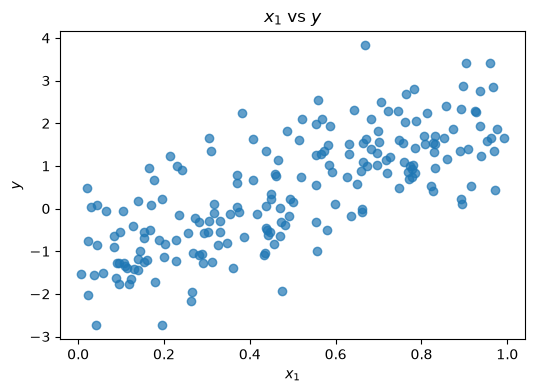

In [42]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["x1"], df["y"], alpha=0.7)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$y$")
ax.set_title("$x_1$ vs $y$")
plt.show()

### Exercise 4: Explore all features

1. Plot each feature ($x_1, \dots, x_4$) against $y$ on a 2 × 2 grid of subplots.
2. Print the correlation of each feature with $y$.

Which feature appears to have no relationship with $y$?

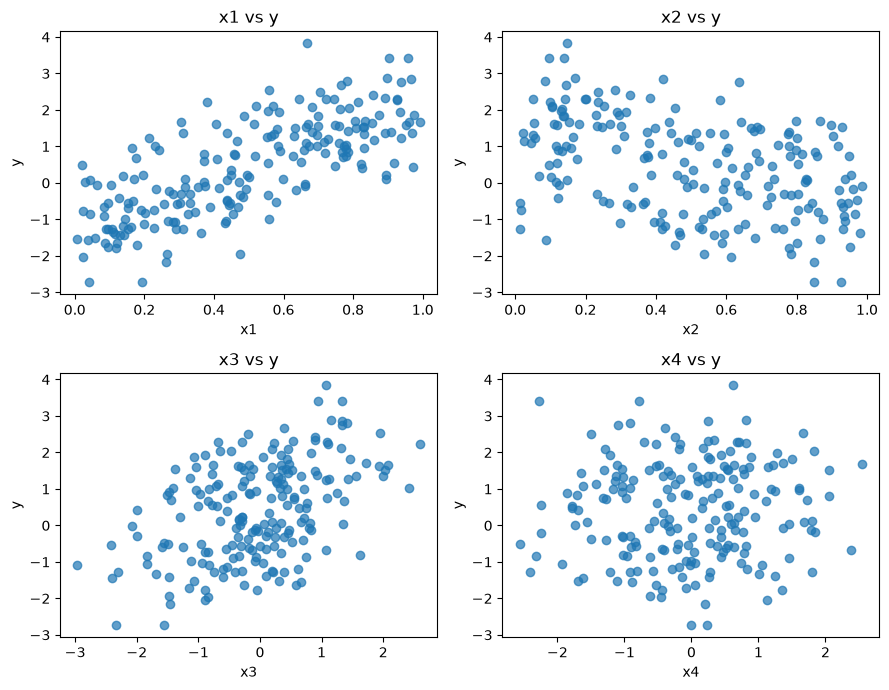

In [44]:
features = ["x1", "x2", "x3", "x4"]

fig, axes = plt.subplots(2, 2, figsize=(9, 7))

for ax, feature in zip(axes.flat, features):
    # TODO: scatter plot of df[feature] against df["y"]
    ax.scatter(df[feature], df["y"], alpha=0.7)
    # TODO: add axis labels and a title
    ax.set_xlabel(feature)
    ax.set_ylabel("y")
    ax.set_title(f"{feature} vs y")

plt.tight_layout()
plt.show()

In [45]:
print(df.corr()["y"].drop("y"))

x1    0.743813
x2   -0.429579
x3    0.467250
x4    0.055863
Name: y, dtype: float64


### Technical - load the data file responses_week1_real.csv and visualise the data 
##### - is the data complete?
##### - what type of data is present? How do you process different types?
##### - which are the most useful data to show? 
##### - plots or tables?
##### - interesting combinations of the data?

In [53]:
responses = pd.read_csv("data.csv")
responses.head()

,x1,x2,x3,x4,y
0,0.773956,0.777405,0.439637,-1.176615,1.008983
1,0.438878,0.971826,0.524188,-0.837463,-0.466381
2,0.858598,0.500741,0.276274,0.235448,1.171235
3,0.697368,0.143898,-1.412766,1.611116,1.022400
4,0.094177,0.013936,-2.310103,-1.222374,-1.273441


In [54]:
responses.shape

(200, 5)

In [55]:
responses.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
x1,200.0,0.493870,0.282312,0.007362,0.252216,0.479004,0.747244,0.992376
x2,200.0,0.499223,0.288395,0.012303,0.236724,0.505428,0.766523,0.986632
x3,200.0,-0.052466,0.997321,-2.964529,-0.708375,-0.041323,0.550454,2.597674
x4,200.0,-0.049941,1.037039,-2.564744,-0.845359,-0.000320,0.637586,2.549328
y,200.0,0.424911,1.324981,-2.728636,-0.590988,0.507701,1.442203,3.835900


In [56]:
missing_summary = pd.DataFrame({
    "missing_count": responses.isna().sum(),
    "missing_percent": responses.isna().mean() * 100,
})

missing_summary.sort_values("missing_count", ascending=False)

,missing_count,missing_percent
x1,0,0.0
x2,0,0.0
x3,0,0.0
x4,0,0.0
y,0,0.0


**Is the data complete?**

No missing values are present as each column has a missing value count of 0 and a missing percentage of 0%.

**What type of data is present? How do you process different types?**

All the columns contain numerical data. The first four are input features whilst `y` is the ouput variable. These were explored using descriptive statistcs, scatter plots and correlations.

**Which are the most useful data to show?**

The most useful comparisons are between each input feature `y` as these help identify which features relate to the output. Comparing all the features is useful as it includes both features used to generate `y`.

**Plots or tables?**
Both are useful. A 2x2 grid of scatter plot allows for comparison between the relationships of each feature and `y`. And a correlation table provides a numerical sumary of those relationships.

**Interesting combinations of data?**
The main comparison of interest are `x1` against `y`, `x2` against `y`, and `x3` aganst `y` as the data-generation equations includes all three.